# PINN Eigen-solver for a 2D Triangular Finite Well (PyTorch)

Adapted from `finite_square_well_2d_eigen.ipynb` (Jin, Mattheakis & Protopapas, arXiv:2203.00451).

$$-\frac12\nabla^2\psi(x,y)+V(x,y)\psi(x,y)=E\psi(x,y),\qquad V(x,y)=\begin{cases}0&(x,y)\in T\\V_0=20&\text{otherwise}\end{cases},\qquad \psi\to0\text{ on }x=\pm6,y=\pm6.$$

Where $T$ is the triangle with vertices $(-1.7,0),(0,1.7),(1.7,0)$, i.e. $T=\{y\ge0,\ y\le1.7-|x|\}$.

**Differences from the square-well version**

- $V$ is not separable, so the reference solution is a 2D finite-difference diagonalization.
- $V$ is symmetric only under $x\to-x$ (not $y\to-y$), so each eigenfunction has an $x$-parity $p_x=\pm1$ and the network embeds only that: $N=W[h(x,y)+p_xh(-x,y)]$.
- The parity of the $k$-th state is not known in advance, so states are found via a **two-candidate search**: keep the lowest not-yet-accepted state of each parity, accept the lower of the two, then search for the next state of that parity.
- Orthogonality to already-found states of the same parity is enforced exactly by Gram–Schmidt projection of the network output (states of opposite parity are orthogonal by symmetry).

**Losses** (as in the reference notebook)

$$L_{DE}=\frac{\frac1M\sum_i\left(-\frac12\nabla^2\psi_i+V_i\psi_i-E\psi_i\right)^2}{\iint\psi^2},\qquad L_{norm}=\left(\sqrt{\iint\psi^2\,dx\,dy}-1\right)^2.$$

- The residual is divided by the norm so it cannot be reduced by shrinking $\psi$.
- Convergence (patience) and acceptance use `L_DE_smooth`, the residual on points farther than `jump_band` from the triangle edges, because a smooth network cannot reproduce the jump of $\nabla^2\psi$ across them.

In [1]:
import copy
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
import torch
import torch.nn as nn
from scipy.interpolate import RegularGridInterpolator
from scipy.sparse.linalg import eigsh

torch.manual_seed(0)
np.random.seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
sns.set_theme(style="whitegrid", context="notebook")
print(f"Using device: {device}")

Using device: mps


In [2]:
# Problem
V0 = 20.0
half_base = 1.7
vertices = np.array([[-half_base, 0.], [0., half_base], [half_base, 0.]])
xL, xR = -6.0, 6.0  # same limits for x and y

# Collocation sampling
n_uniform = 2000
n_box = 4000
box_x, box_y = (-2.5, 2.5), (-0.8, 2.5)  # psi is negligible outside this box
n_edge = 1500
edge_band = 0.2

# Network / optimizer
hidden = 64
omega = 6.0  # input frequency scale for the sin network; resolves sharp features
lr = 8e-3
lr_decay_every, lr_min = 3000, 1e-4  # halve lr every N epochs within each state search
nu_norm = 1.0

# Solution recognition
n_states = 4
window = 1000
patience_tol = 1e-2  # relative improvement of mean L_DE_smooth between consecutive windows
de_tol = 5e-2  # applied to L_DE_smooth
jump_band = 0.05  # points closer than this to a triangle edge are excluded from L_DE_smooth
norm_tol = 5e-3
min_epochs = 6000
max_epochs_per_state = 20000
max_retries = 3

In [3]:
class Sin(nn.Module):
    def forward(self, x):
        return torch.sin(x)


def g_boundary(s):
    return (1 - torch.exp(-(s - xL))) * (1 - torch.exp(s - xR))


class EigenNet2D(nn.Module):
    """psi(x, y) = g(x) g(y) N(x, y, E) with trainable E and embedded x-parity px."""

    def __init__(self, hidden=64, parity=1):
        super().__init__()
        self.parity = parity
        self.E = nn.Linear(1, 1)
        self.hidden = nn.Sequential(nn.Linear(3, hidden), Sin(), nn.Linear(hidden, hidden), Sin())
        self.out = nn.Linear(hidden, 1)

    def energy(self):
        return self.E(torch.ones(1, 1, device=self.E.weight.device)).squeeze()

    def forward(self, xy):
        x, y = xy[:, :1], xy[:, 1:]
        E = self.E(torch.ones_like(x))
        h = self.hidden(torch.cat([omega * x, omega * y, E], 1))
        h_mirror = self.hidden(torch.cat([-omega * x, omega * y, E], 1))
        return g_boundary(x) * g_boundary(y) * self.out(h + self.parity * h_mirror)


# Fixed quadrature grid on the box, used for Gram-Schmidt coefficients
_qx = torch.linspace(*box_x, 81, device=device)
_qy = torch.linspace(*box_y, 61, device=device)
quad_grid = torch.stack(torch.meshgrid(_qx, _qy, indexing="ij"), -1).reshape(-1, 2)


class Orthogonalized(nn.Module):
    """Network output with already-found same-parity eigenstates projected out (Gram-Schmidt)."""

    def __init__(self, net, basis):
        super().__init__()
        self.net = net
        self.basis = nn.ModuleList(basis)
        self.parity = net.parity

    def energy(self):
        return self.net.energy()

    def forward(self, xy):
        psi = self.net(xy)
        psi_q = self.net(quad_grid)
        # coefficients come from the fixed grid, so they are constants w.r.t. xy and the Laplacian stays exact
        for phi in self.basis:
            phi_q = phi(quad_grid)
            c = (phi_q * psi_q).sum() / (phi_q**2).sum()
            psi = psi - c * phi(xy)
            psi_q = psi_q - c * phi_q
        return psi


def inside_triangle_np(x, y):
    return (y >= 0) & (y <= half_base - np.abs(x))


def potential_np(x, y):
    return np.where(inside_triangle_np(x, y), 0.0, V0)


def potential(xy):
    x, y = xy[:, :1], xy[:, 1:]
    inside = (y >= 0) & (y <= half_base - torch.abs(x))
    return torch.where(inside, torch.zeros_like(x), V0 * torch.ones_like(x))

In [4]:
tri = torch.tensor(vertices, dtype=torch.float32, device=device)
edge_a, edge_b = tri, tri.roll(-1, dims=0)
edge_vec = edge_b - edge_a
edge_len = edge_vec.norm(dim=1)
edge_normal = torch.stack([-edge_vec[:, 1], edge_vec[:, 0]], 1) / edge_len[:, None]


def distance_to_edges(xy):
    rel = xy[:, None, :] - edge_a[None]
    t = ((rel * edge_vec[None]).sum(-1) / edge_len**2).clamp(0, 1)
    return (rel - t[..., None] * edge_vec[None]).norm(dim=-1).min(dim=1).values


box_area = (box_x[1] - box_x[0]) * (box_y[1] - box_y[0])
box_slice = slice(n_uniform, n_uniform + n_box)
box_lo = torch.tensor([box_x[0], box_y[0]], device=device)
box_hi = torch.tensor([box_x[1], box_y[1]], device=device)


def sample_points():
    uniform = xL + (xR - xL) * torch.rand(n_uniform, 2, device=device)
    box = box_lo + (box_hi - box_lo) * torch.rand(n_box, 2, device=device)
    # points on the triangle edges (length-weighted) with a random normal offset
    k = torch.multinomial(edge_len, n_edge, replacement=True)
    t = torch.rand(n_edge, 1, device=device)
    offset = edge_band * (2 * torch.rand(n_edge, 1, device=device) - 1)
    edge = edge_a[k] + t * edge_vec[k] + offset * edge_normal[k]
    return torch.cat([uniform, box, edge]).requires_grad_(True)


def compute_losses(model, xy):
    psi = model(xy)
    E = model.energy()
    grad = torch.autograd.grad(psi, xy, torch.ones_like(psi), create_graph=True)[0]
    psi_xx = torch.autograd.grad(grad[:, 0], xy, torch.ones_like(grad[:, 0]), create_graph=True)[0][:, :1]
    psi_yy = torch.autograd.grad(grad[:, 1], xy, torch.ones_like(grad[:, 1]), create_graph=True)[0][:, 1:]
    res2 = (-0.5 * (psi_xx + psi_yy) + potential(xy) * psi - E * psi)**2
    L_de_smooth = torch.mean(res2.detach()[distance_to_edges(xy.detach()) > jump_band])

    norm2 = torch.mean(psi[box_slice] ** 2) * box_area
    L_de = torch.mean(res2) / norm2
    # sqrt form keeps a non-zero gradient at the trivial solution psi = 0
    L_norm = (torch.sqrt(norm2) - 1.) ** 2
    return L_de, L_norm, L_de_smooth

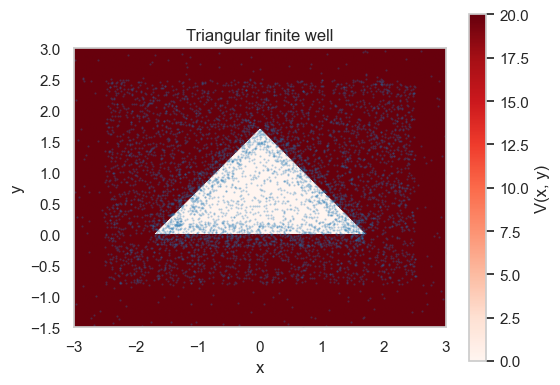

In [5]:
xp, yp = np.meshgrid(np.linspace(-3, 3, 400), np.linspace(-1.5, 3, 300))
fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(potential_np(xp, yp), origin="lower", cmap="Reds", extent=[-3, 3, -1.5, 3])
with torch.no_grad():
    pts = sample_points().cpu().numpy()
ax.scatter(pts[:, 0], pts[:, 1], s=0.3, color="tab:blue", alpha=0.3, label="collocation sample")
fig.colorbar(im, ax=ax, label="V(x, y)")
ax.set(xlim=(-3, 3), ylim=(-1.5, 3), xlabel="x", ylabel="y", title="Triangular finite well")
ax.grid(False)
plt.show()

## Training

`train_state(parity)` trains one fresh network of the given $x$-parity, orthogonal to the already-accepted states of that parity, until the patience condition is met. It returns the state if `L_DE_smooth` and `L_norm` are below their thresholds; otherwise it is a false solution.

Two-candidate search for the lowest `n_states` states: keep the next state of each parity as a candidate, accept the lower-energy candidate, and search for a replacement candidate of that parity. Each accepted state is therefore the lowest remaining state overall.

In [6]:
def set_lr(opt, epochs_in_state):
    for group in opt.param_groups:
        group['lr'] = max(lr * 0.5 ** (epochs_in_state // lr_decay_every), lr_min)


def train_state(parity):
    basis = [m for _, m in found if m.parity == parity]
    model = Orthogonalized(EigenNet2D(hidden, parity), basis).to(device)
    optimizer = torch.optim.Adam(model.net.parameters(), lr=lr)
    de_hist = []
    for it in range(1, max_epochs_per_state + 1):
        L_de, L_norm, L_de_smooth = compute_losses(model, sample_points())
        loss = L_de + nu_norm * L_norm
        set_lr(optimizer, it)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        E = model.energy().item()
        de_hist.append(L_de_smooth.item())
        history.append({'epoch': len(history), 'E': E, 'L_DE': L_de.item(), 'L_DE_smooth': L_de_smooth.item(),
                        'L_norm': L_norm.item(), 'parity': parity})
        if it % 500 == 0:
            print(f"  it {it:6d} | parity {parity:+d} | E {E:.4f} | L_DE {L_de.item():.2e} |"
                  f" L_DE_smooth {L_de_smooth.item():.2e} | L_norm {L_norm.item():.2e} | {time.time()-t_start:.0f}s")
        if it < max(min_epochs, 2 * window):
            continue
        prev, curr = np.mean(de_hist[-2 * window:-window]), np.mean(de_hist[-window:])
        if (prev - curr) / prev > patience_tol:
            continue
        if curr < de_tol and L_norm.item() < norm_tol:
            events.append({'epoch': len(history) - 1, 'event': 'converged', 'E': E})
            print(f" >> converged E = {E:.4f} (parity {parity:+d})")
            return E, copy.deepcopy(model).eval().requires_grad_(False)
        break
    events.append({'epoch': len(history) - 1, 'event': 'rejected', 'E': E})
    print(f" >> false solution E = {E:.4f} (parity {parity:+d}), L_DE_smooth {np.mean(de_hist[-window:]):.2e},"
          f" L_norm {L_norm.item():.1e}")
    return None


found, history, events = [], [], []
candidates = {}
t_start = time.time()

while len(found) < n_states:
    for parity in (+1, -1):
        if parity in candidates:
            continue
        for _ in range(max_retries):
            result = train_state(parity)
            if result is not None:
                candidates[parity] = result
                break
    if not candidates:
        print("No candidate could be found; stopping.")
        break
    best = min(candidates, key=lambda p: candidates[p][0])
    E_best, model_best = candidates.pop(best)
    found.append((E_best, model_best))
    events.append({'epoch': len(history) - 1, 'event': 'accepted', 'E': E_best})
    print(f" ++ accepted state {len(found) - 1}: E = {E_best:.4f} (parity {best:+d})")

print(f"Found {len(found)} states in {time.time() - t_start:.0f}s: "
      f"{[(round(E, 4), m.parity) for E, m in found]}")

  it    500 | parity +1 | E 2.3576 | L_DE 1.78e-01 | L_DE_smooth 6.72e-02 | L_norm 1.95e-04 | 23s
  it   1000 | parity +1 | E 2.7080 | L_DE 1.48e-01 | L_DE_smooth 5.06e-02 | L_norm 2.51e-04 | 34s
  it   1500 | parity +1 | E 2.7223 | L_DE 1.24e-01 | L_DE_smooth 2.32e-02 | L_norm 1.09e-03 | 45s
  it   2000 | parity +1 | E 2.7348 | L_DE 1.07e-01 | L_DE_smooth 4.75e-02 | L_norm 7.04e-05 | 56s
  it   2500 | parity +1 | E 2.7484 | L_DE 9.84e-02 | L_DE_smooth 2.69e-02 | L_norm 1.83e-03 | 67s
  it   3000 | parity +1 | E 2.7640 | L_DE 1.08e-01 | L_DE_smooth 4.17e-02 | L_norm 1.52e-03 | 78s
  it   3500 | parity +1 | E 2.7645 | L_DE 7.81e-02 | L_DE_smooth 1.52e-02 | L_norm 3.95e-04 | 89s
  it   4000 | parity +1 | E 2.7712 | L_DE 7.29e-02 | L_DE_smooth 1.67e-02 | L_norm 4.35e-04 | 99s
  it   4500 | parity +1 | E 2.7696 | L_DE 7.18e-02 | L_DE_smooth 1.58e-02 | L_norm 5.87e-05 | 110s
  it   5000 | parity +1 | E 2.7758 | L_DE 6.65e-02 | L_DE_smooth 1.86e-02 | L_norm 2.60e-03 | 121s
  it   5500 | pari

## Reference solution

Second-order finite differences for $-
rac12
abla^2+V$ on a sub-domain $[-3,3]	imes[-1.5,3.2]$ with Dirichlet boundaries (the eigenfunctions decay like $e^{-\kappa x}$ with $\kappapprox5$–$6$, so the truncation changes $E$ negligibly), solved with shift-invert `eigsh`. The slanted edges are represented on the Cartesian grid.

In [7]:
h_fd = 0.015
xs_fd = np.arange(-3.0 + h_fd / 2, 3.0, h_fd)[:-1]
ys_fd = np.arange(-1.5 + h_fd / 2, 3.2, h_fd)[:-1]
X_fd, Y_fd = np.meshgrid(xs_fd, ys_fd, indexing="ij")


def lap_1d(n):
    return sp.diags([np.ones(n - 1), -2 * np.ones(n), np.ones(n - 1)], [-1, 0, 1]) / h_fd**2


Lapp = sp.kron(lap_1d(len(xs_fd)), sp.identity(len(ys_fd))) + sp.kron(sp.identity(len(xs_fd)), lap_1d(len(ys_fd)))
H = (-0.5 * Lapp + sp.diags(potential_np(X_fd, Y_fd).ravel())).tocsc()
n_ref = n_states + 4
E_fd, vec_fd = eigsh(H, k=n_ref, sigma=0, which="LM")
order = np.argsort(E_fd)
E_fd, vec_fd = E_fd[order], vec_fd[:, order]

# Evaluation grid on the box
sx = np.linspace(*box_x, 201)
sy = np.linspace(*box_y, 133)
X_np, Y_np = np.meshgrid(sx, sy, indexing="ij")


def normalize_2d(psi):
    return psi / np.sqrt(np.trapezoid(np.trapezoid(psi**2, sy, axis=1), sx))


ref_states = []
for k in range(n_ref):
    psi_k = vec_fd[:, k].reshape(X_fd.shape)
    parity = int(np.sign(np.sum(psi_k * psi_k[::-1, :])))
    psi_box = RegularGridInterpolator((xs_fd, ys_fd), psi_k)(np.stack([X_np, Y_np], -1))
    ref_states.append({'k': k, 'E': E_fd[k], 'parity': parity, 'psi': normalize_2d(psi_box)})

print("Reference states:", [(round(s['E'], 4), 'even' if s['parity'] > 0 else 'odd') for s in ref_states])

Reference states: [(np.float64(2.8191), 'even'), (np.float64(5.5956), 'odd'), (np.float64(7.2354), 'even'), (np.float64(9.385), 'even'), (np.float64(10.9976), 'odd'), (np.float64(13.5627), 'even'), (np.float64(14.0571), 'odd'), (np.float64(15.5365), 'even')]


In [8]:
xy_t = torch.tensor(np.stack([X_np.ravel(), Y_np.ravel()], 1), dtype=torch.float32, device=device)
rows, psi_pinn, psi_ref = [], [], []
for E_p, m in sorted(found, key=lambda s: s[0]):
    ref = min((s for s in ref_states if s['parity'] == m.parity), key=lambda s: abs(s['E'] - E_p))
    with torch.no_grad():
        psi = normalize_2d(m(xy_t).cpu().numpy().reshape(X_np.shape))
    # Global sign of an eigenfunction is arbitrary
    if np.sum(psi * ref['psi']) < 0:
        psi = -psi
    psi_pinn.append(psi)
    psi_ref.append(ref['psi'])
    rows.append({'ref state': ref['k'], 'parity': 'even' if m.parity > 0 else 'odd', 'E_PINN': E_p,
                 'E_ref': ref['E'], 'E rel. err (%)': 100 * abs(E_p - ref['E']) / ref['E'],
                 'MSE w max|psi_ref|': np.mean((psi - ref['psi']) ** 2) / np.max(np.abs(ref['psi'])) ** 2})

df_results = pd.DataFrame(rows)
df_results

,ref state,parity,E_PINN,E_ref,E rel. err (%),MSE w max|psi_ref|
0,0,even,2.780199,2.819078,1.379161,0.000047
1,1,odd,5.541007,5.595607,0.975760,0.000081
2,2,even,7.170796,7.235383,0.892652,0.000326
3,3,even,9.289476,9.384993,1.017761,0.000340


In [9]:
overlap = np.array([[np.trapezoid(np.trapezoid(a * b, sy, axis=1), sx) for b in psi_pinn] for a in psi_pinn])
labels = [f"n={k}" for k in df_results['ref state']]
pd.DataFrame(overlap, index=labels, columns=labels).round(4)

,n=0,n=1,n=2,n=3
n=0,1.0000,-0.0009,-0.0000,-0.0000
n=1,-0.0009,1.0000,0.0002,0.0005
n=2,-0.0000,0.0002,1.0000,-0.0000
n=3,-0.0000,0.0005,-0.0000,1.0000


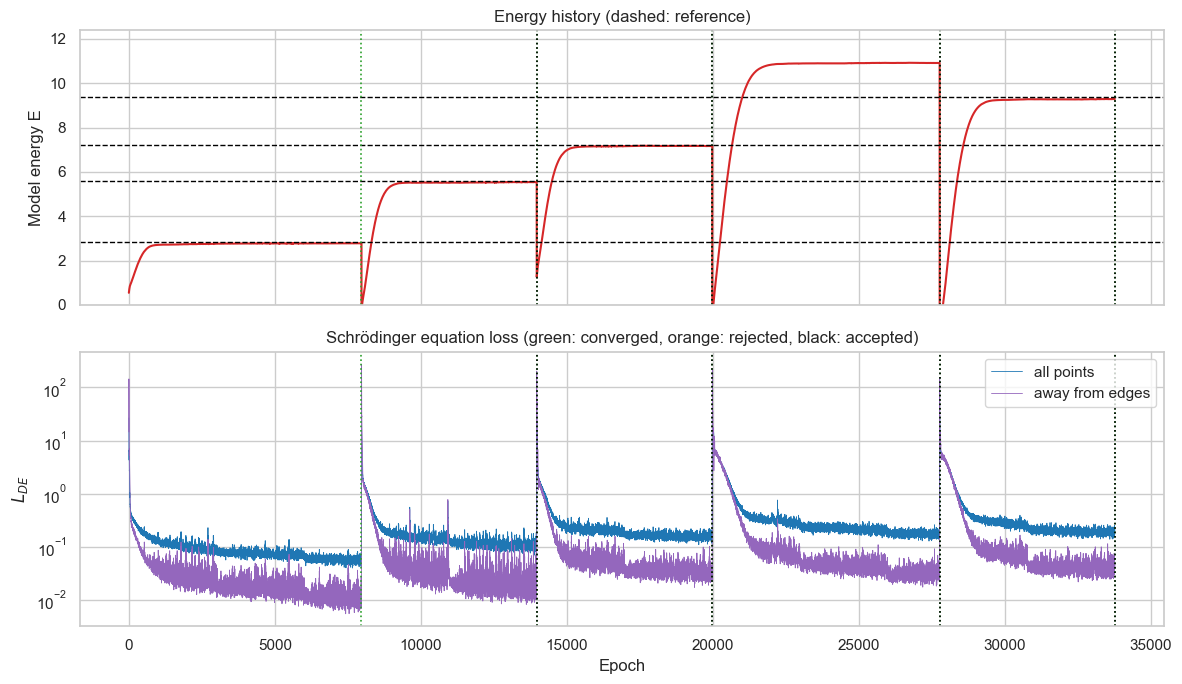

In [10]:
df_hist = pd.DataFrame(history)
df_events = pd.DataFrame(events)
E_ref_lowest = [s['E'] for s in ref_states[:n_states]]
colors = {'converged': 'tab:green', 'rejected': 'tab:orange', 'accepted': 'black'}

fig, (ax_E, ax_L) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
sns.lineplot(data=df_hist, x='epoch', y='E', color='tab:red', ax=ax_E)
for E_k in E_ref_lowest:
    ax_E.axhline(E_k, color='black', linestyle='--', linewidth=1)
ax_E.set(ylim=(0, max(E_ref_lowest) + 3), ylabel="Model energy E", title="Energy history (dashed: reference)")

sns.lineplot(data=df_hist, x='epoch', y='L_DE', color='tab:blue', linewidth=0.6, ax=ax_L, label='all points')
sns.lineplot(data=df_hist, x='epoch', y='L_DE_smooth', color='tab:purple', linewidth=0.6, ax=ax_L,
             label='away from edges')
for _, ev in df_events.iterrows():
    for a in (ax_E, ax_L):
        a.axvline(ev['epoch'], color=colors[ev['event']], linestyle=':', linewidth=1.2)
ax_L.set(yscale='log', xlabel="Epoch", ylabel=r"$L_{DE}$",
         title="Schrödinger equation loss (green: converged, orange: rejected, black: accepted)")
plt.tight_layout()
plt.show()

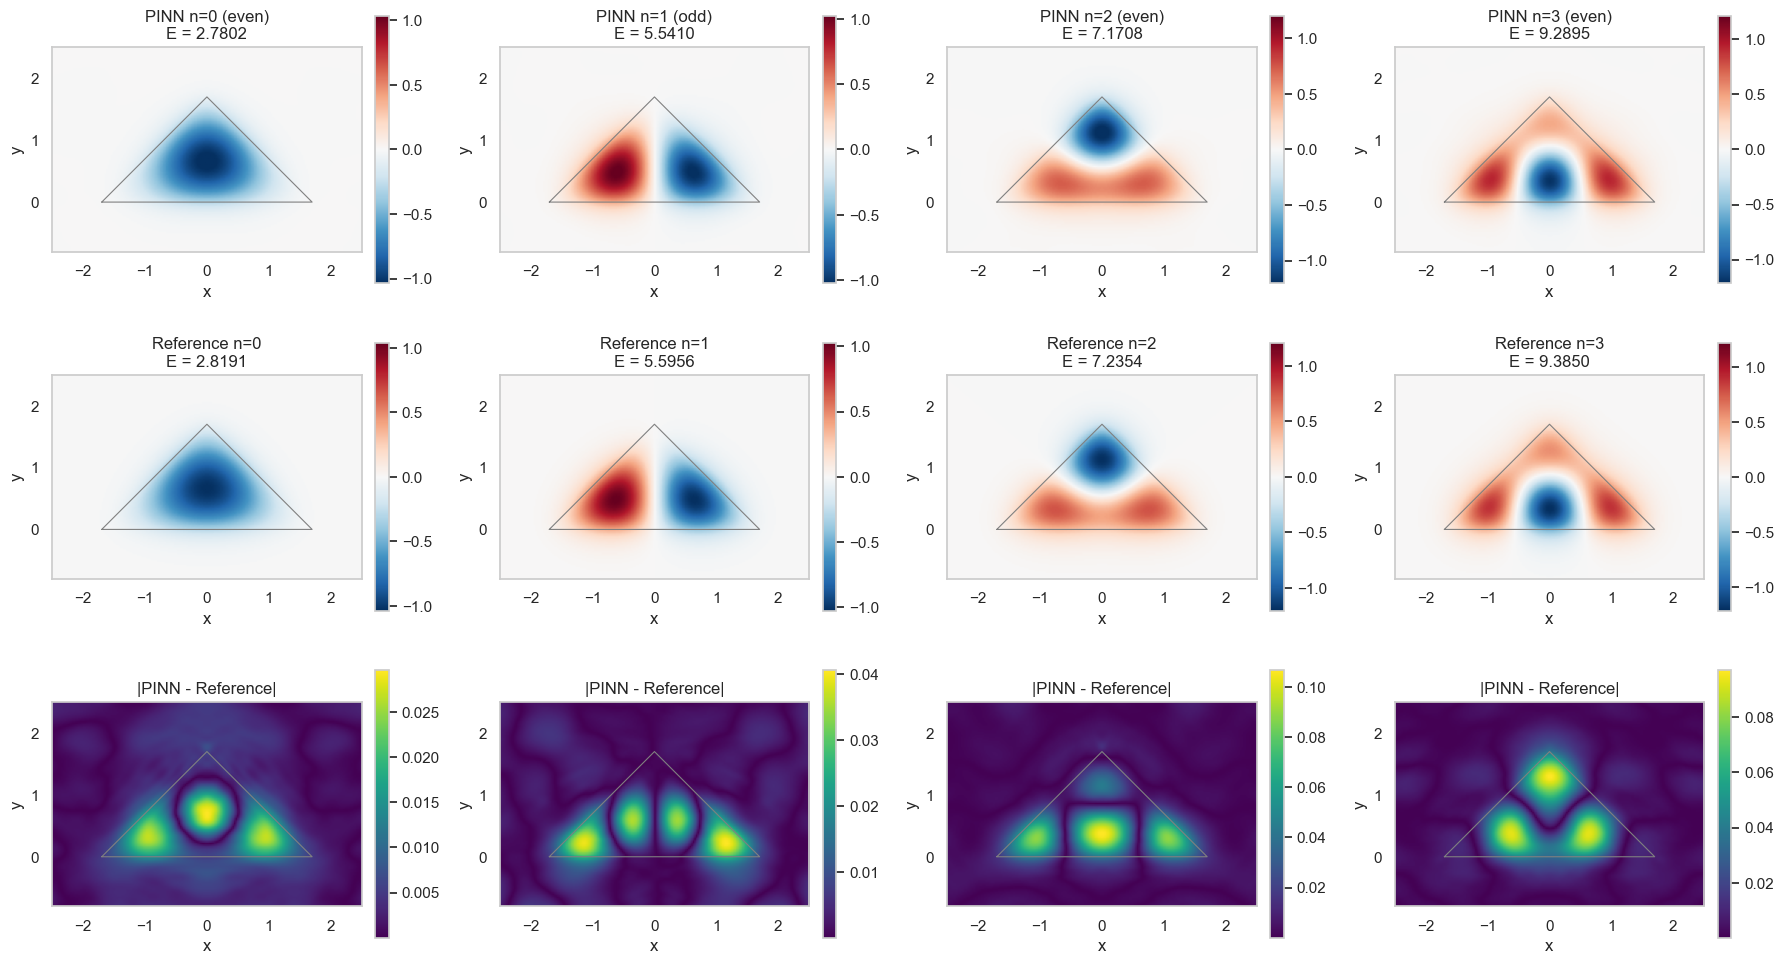

In [11]:
n_found = len(psi_pinn)
fig, axes = plt.subplots(3, n_found, figsize=(4.5 * n_found, 10), squeeze=False)
extent = [box_x[0], box_x[1], box_y[0], box_y[1]]
outline = np.vstack([vertices, vertices[:1]])

for col, row in df_results.iterrows():
    vmax = np.max(np.abs(psi_ref[col]))
    panels = [
        (psi_pinn[col], f"PINN n={row['ref state']} ({row['parity']})\nE = {row['E_PINN']:.4f}", 'RdBu_r', -vmax, vmax),
        (psi_ref[col], f"Reference n={row['ref state']}\nE = {row['E_ref']:.4f}", 'RdBu_r', -vmax, vmax),
        (np.abs(psi_pinn[col] - psi_ref[col]), '|PINN - Reference|', 'viridis', None, None),
    ]
    for r, (data, title, cmap, vmin, vmax_) in enumerate(panels):
        ax = axes[r, col]
        # arrays are indexed [x, y]; transpose so x is horizontal
        im = ax.imshow(data.T, origin='lower', extent=extent, cmap=cmap, vmin=vmin, vmax=vmax_, aspect='equal')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        ax.plot(outline[:, 0], outline[:, 1], color='gray', linewidth=0.8)
        ax.set(title=title, xlabel='x', ylabel='y')
        ax.grid(False)

plt.tight_layout()
plt.show()

In [14]:
fig.savefig("triangular_finite_well_PINN_results.png", bbox_inches="tight")